<a href="https://colab.research.google.com/github/AnshG-19/Blackhole_simulator_rayTracing/blob/main/notebooks/07_performance_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import os
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

repo_path = "/content/Blackhole_simulator_rayTracing"

if not os.path.exists(repo_path):
    %cd /content
    !git clone https://github.com/AnshG-19/Blackhole_simulator_rayTracing.git

os.chdir(repo_path)

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

from src.physics.ray_tracing import calculate_light_ray

print("Repository connected:", os.getcwd())
print("Light-ray solver imported successfully.")


/content
Cloning into 'Blackhole_simulator_rayTracing'...
remote: Enumerating objects: 100, done.
remote: Counting objects: 100% (100/100), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 100 (delta 37), reused 16 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (100/100), 3.07 MiB | 12.04 MiB/s, done.
Resolving deltas: 100% (37/37), done.
Repository connected: /content/Blackhole_simulator_rayTracing
Light-ray solver imported successfully.


In [2]:

# Test different numerical resolutions
point_counts = [100, 250, 500, 1000, 1500, 2000, 3000]

execution_times = []

for points in point_counts:
    start_time = time.perf_counter()

    ray = calculate_light_ray(
        mass_parameter=1.0,
        impact_parameter=8.0,
        max_angle=2.6,
        points=points,
    )

    end_time = time.perf_counter()
    elapsed = end_time - start_time

    execution_times.append(elapsed)

    print(
        f"Points: {points:4d} | "
        f"Time: {elapsed:.6f} seconds | "
        f"Actual samples: {len(ray['x'])}"
    )


Points:  100 | Time: 0.056545 seconds | Actual samples: 101
Points:  250 | Time: 0.011694 seconds | Actual samples: 251
Points:  500 | Time: 0.006599 seconds | Actual samples: 501
Points: 1000 | Time: 0.010946 seconds | Actual samples: 1001
Points: 1500 | Time: 0.009120 seconds | Actual samples: 1501
Points: 2000 | Time: 0.010087 seconds | Actual samples: 2001
Points: 3000 | Time: 0.018369 seconds | Actual samples: 3001


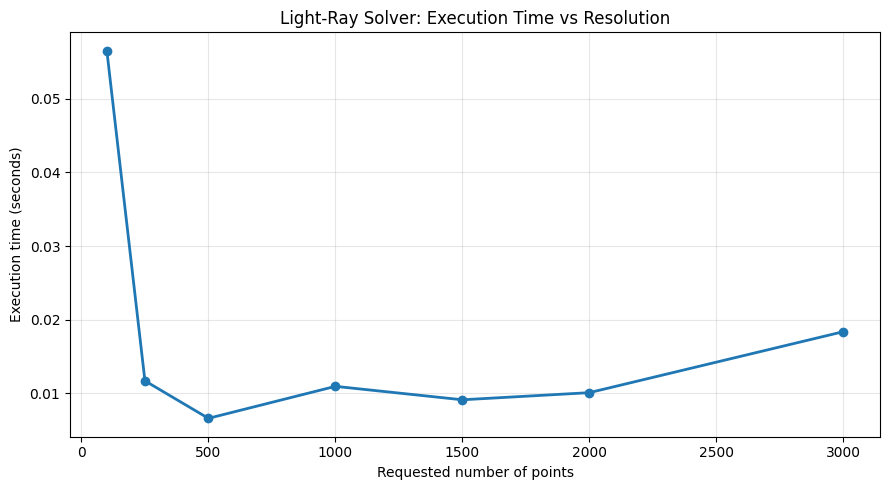

In [3]:

plt.figure(figsize=(9, 5))

plt.plot(
    point_counts,
    execution_times,
    marker="o",
    linewidth=2,
)

plt.xlabel("Requested number of points")
plt.ylabel("Execution time (seconds)")
plt.title("Light-Ray Solver: Execution Time vs Resolution")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:

import statistics

repeats = 5
median_times = []

for points in point_counts:
    timings = []

    # One warm-up run to reduce first-run overhead
    calculate_light_ray(
        mass_parameter=1.0,
        impact_parameter=8.0,
        max_angle=2.6,
        points=points,
    )

    for _ in range(repeats):
        start_time = time.perf_counter()

        calculate_light_ray(
            mass_parameter=1.0,
            impact_parameter=8.0,
            max_angle=2.6,
            points=points,
        )

        timings.append(time.perf_counter() - start_time)

    median_time = statistics.median(timings)
    median_times.append(median_time)

    print(
        f"Points: {points:4d} | "
        f"Median time: {median_time:.6f} seconds"
    )


Points:  100 | Median time: 0.002607 seconds
Points:  250 | Median time: 0.002124 seconds
Points:  500 | Median time: 0.002350 seconds
Points: 1000 | Median time: 0.002437 seconds
Points: 1500 | Median time: 0.005089 seconds
Points: 2000 | Median time: 0.004120 seconds
Points: 3000 | Median time: 0.003347 seconds


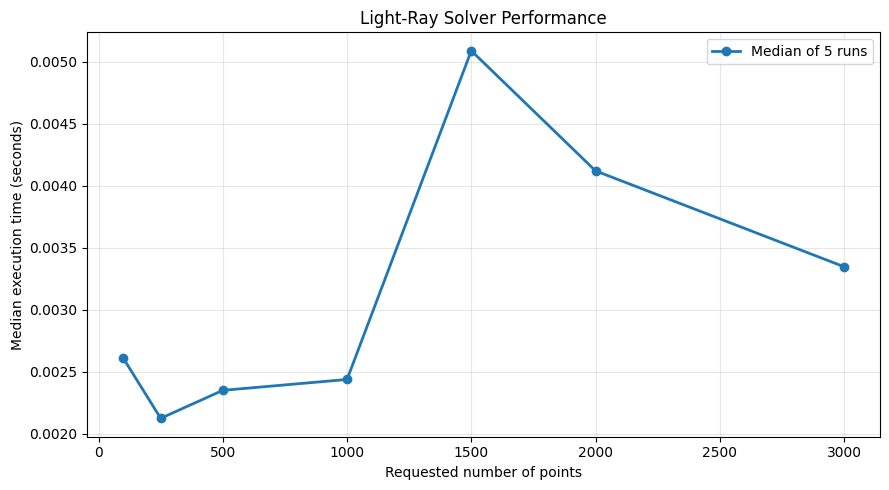

In [5]:

plt.figure(figsize=(9, 5))

plt.plot(
    point_counts,
    median_times,
    marker="o",
    linewidth=2,
    label="Median of 5 runs",
)

plt.xlabel("Requested number of points")
plt.ylabel("Median execution time (seconds)")
plt.title("Light-Ray Solver Performance")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [6]:

print(f"{'Points':>10} | {'Median time (s)':>16}")
print("-" * 30)

for points, elapsed in zip(point_counts, median_times):
    print(f"{points:10d} | {elapsed:16.6f}")


    Points |  Median time (s)
------------------------------
       100 |         0.002607
       250 |         0.002124
       500 |         0.002350
      1000 |         0.002437
      1500 |         0.005089
      2000 |         0.004120
      3000 |         0.003347


## Performance Experiment: Conclusion

This experiment measured the execution time of the Schwarzschild light-ray solver at numerical resolutions ranging from 100 to 3000 requested points.

The solver completed all tested calculations successfully. After a warm-up run, five measurements were collected at each resolution, and their median was used to reduce the influence of unusually slow runs.

The measured median execution times ranged from approximately 0.0021 to 0.0051 seconds. Execution time did not increase monotonically with the requested number of points. This is expected for a short benchmark because fixed computational overhead, adaptive numerical integration, and runtime variability can influence the results.

Overall, the solver is fast for the tested configurations. More extensive experiments, with additional repetitions and larger resolutions, would be needed to characterize its scaling reliably. Increasing the requested number of points also does not guarantee a proportional increase in numerical accuracy; accuracy should be evaluated separately against a suitable reference solution.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

Create a benchmark function
Why make this a function?
We want to run exactly the same calculation at different resolutions. Putting it in a function avoids duplicating code and makes the experiment easier to extend.

The returned brightness array represents an image: each array element corresponds to a pixel.

In [ ]:
def calculate_disk_brightness(resolution):
    # Black hole and disk parameters in geometric units
    r_inner = 6.0
    r_outer = 20.0

    # Create the coordinate grid
    x = np.linspace(-r_outer, r_outer, resolution)
    y = np.linspace(-r_outer, r_outer, resolution)
    X, Y = np.meshgrid(x, y)

    # Distance from the center
    R = np.sqrt(X**2 + Y**2)

    # Select the pixels inside the disk
    mask = (R >= r_inner) & (R <= r_outer)

    # Calculate brightness
    brightness = np.zeros_like(R)
    brightness[mask] = (
        (r_inner / R[mask])**3
        * (1 - np.sqrt(r_inner / R[mask]))
    )

    return brightness

Measure execution time at different resolutions
Understand the code
- start_time records when the calculation begins.
- end_time records when it finishes.
- Subtracting them gives the elapsed time in seconds.
- times stores the measurements so we can plot them later.

In [ ]:
resolutions = [100, 200, 400, 600, 800, 1000]

times = []

# Warm up NumPy before measuring
calculate_disk_brightness(100)

for resolution in resolutions:
    start_time = time.perf_counter()

    brightness = calculate_disk_brightness(resolution)

    end_time = time.perf_counter()

    elapsed = end_time - start_time
    times.append(elapsed)

    print(
        f"Resolution: {resolution:4d} x {resolution:4d} | "
        f"Time: {elapsed:.4f} seconds"
    )

Resolution:  100 x  100 | Time: 0.0008 seconds
Resolution:  200 x  200 | Time: 0.0057 seconds
Resolution:  400 x  400 | Time: 0.0101 seconds
Resolution:  600 x  600 | Time: 0.0231 seconds
Resolution:  800 x  800 | Time: 0.0384 seconds
Resolution: 1000 x 1000 | Time: 0.0530 seconds


Step 4 — Plot the performance results
Notice that resolution is measured per side. A 1000 × 1000 image has one million pixels, whereas a 500 × 500 image has only 250,000 pixels.

The number of pixels grows quadratically with resolution:
\[
N_{\text{pixels}} = N^2
\]

Doubling the resolution therefore means four times as many pixels to process. Actual execution time won't necessarily scale by exactly four because memory allocation, caching, and other overheads also matter.

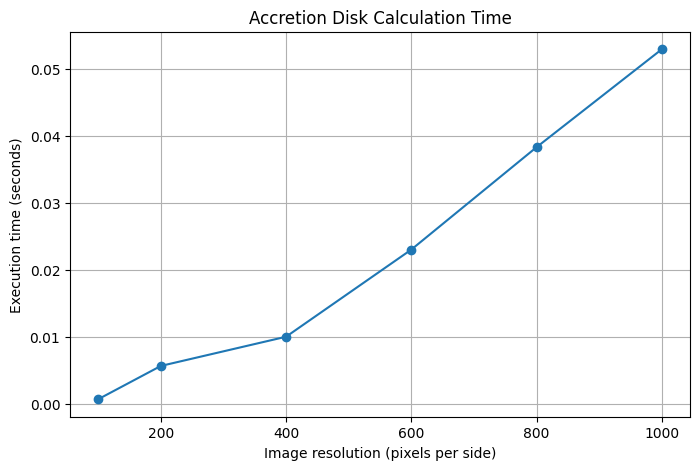

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    resolutions,
    times,
    marker="o"
)

plt.title("Accretion Disk Calculation Time")
plt.xlabel("Image resolution (pixels per side)")
plt.ylabel("Execution time (seconds)")
plt.grid(True)

plt.show()

Compare vectorized calculations with Python loops
NumPy's vectorized operations calculate many values using optimized array operations. Let's compare that with explicitly processing each pixel in Python.

For this experiment, we'll use smaller images because nested Python loops are considerably slower.

In [ ]:
def calculate_disk_vectorized(resolution):
    r_inner = 6.0
    r_outer = 20.0

    x = np.linspace(-r_outer, r_outer, resolution)
    y = np.linspace(-r_outer, r_outer, resolution)
    X, Y = np.meshgrid(x, y)

    R = np.sqrt(X**2 + Y**2)

    brightness = np.zeros_like(R)
    mask = (R >= r_inner) & (R <= r_outer)

    brightness[mask] = (
        (r_inner / R[mask])**3
        * (1 - np.sqrt(r_inner / R[mask]))
    )

    return brightness


def calculate_disk_loops(resolution):
    r_inner = 6.0
    r_outer = 20.0

    x = np.linspace(-r_outer, r_outer, resolution)
    y = np.linspace(-r_outer, r_outer, resolution)

    brightness = np.zeros((resolution, resolution))

    for row in range(resolution):
        for col in range(resolution):
            radius = np.sqrt(x[col]**2 + y[row]**2)

            if r_inner <= radius <= r_outer:
                brightness[row, col] = (
                    (r_inner / radius)**3
                    * (1 - np.sqrt(r_inner / radius))
                )

    return brightness

In [ ]:
small_resolutions = [50, 100, 150, 200]

vectorized_times = []
loop_times = []

for resolution in small_resolutions:
    start = time.perf_counter()
    calculate_disk_vectorized(resolution)
    vectorized_times.append(time.perf_counter() - start)

    start = time.perf_counter()
    calculate_disk_loops(resolution)
    loop_times.append(time.perf_counter() - start)

    print(
        f"{resolution} x {resolution}: "
        f"NumPy = {vectorized_times[-1]:.4f}s, "
        f"Python loops = {loop_times[-1]:.4f}s"
    )

50 x 50: NumPy = 0.0009s, Python loops = 0.0086s
100 x 100: NumPy = 0.0010s, Python loops = 0.0294s
150 x 150: NumPy = 0.0010s, Python loops = 0.0654s
200 x 200: NumPy = 0.0017s, Python loops = 0.1370s


In [ ]:
vectorized_result = calculate_disk_vectorized(100)
loop_result = calculate_disk_loops(100)

print(
    "Maximum absolute difference:",
    np.max(np.abs(vectorized_result - loop_result))
)

print(
    "Outputs match:",
    np.allclose(vectorized_result, loop_result)
)

Maximum absolute difference: 0.0
Outputs match: True


Plot the comparison

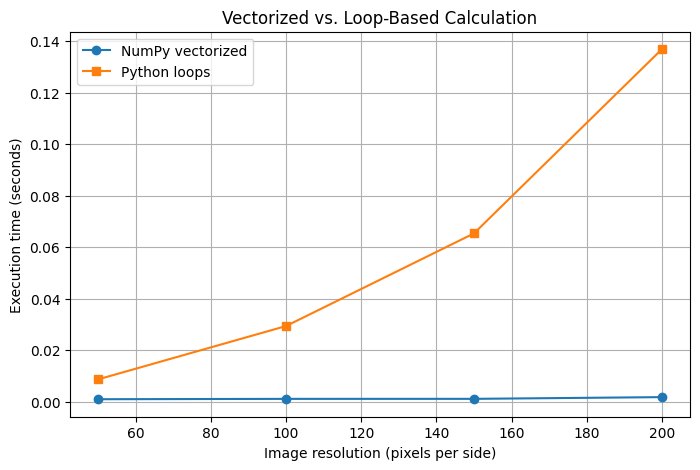

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    small_resolutions,
    vectorized_times,
    marker="o",
    label="NumPy vectorized"
)

plt.plot(
    small_resolutions,
    loop_times,
    marker="s",
    label="Python loops"
)

plt.title("Vectorized vs. Loop-Based Calculation")
plt.xlabel("Image resolution (pixels per side)")
plt.ylabel("Execution time (seconds)")
plt.legend()
plt.grid(True)

plt.show()

Explore the visual quality trade-off

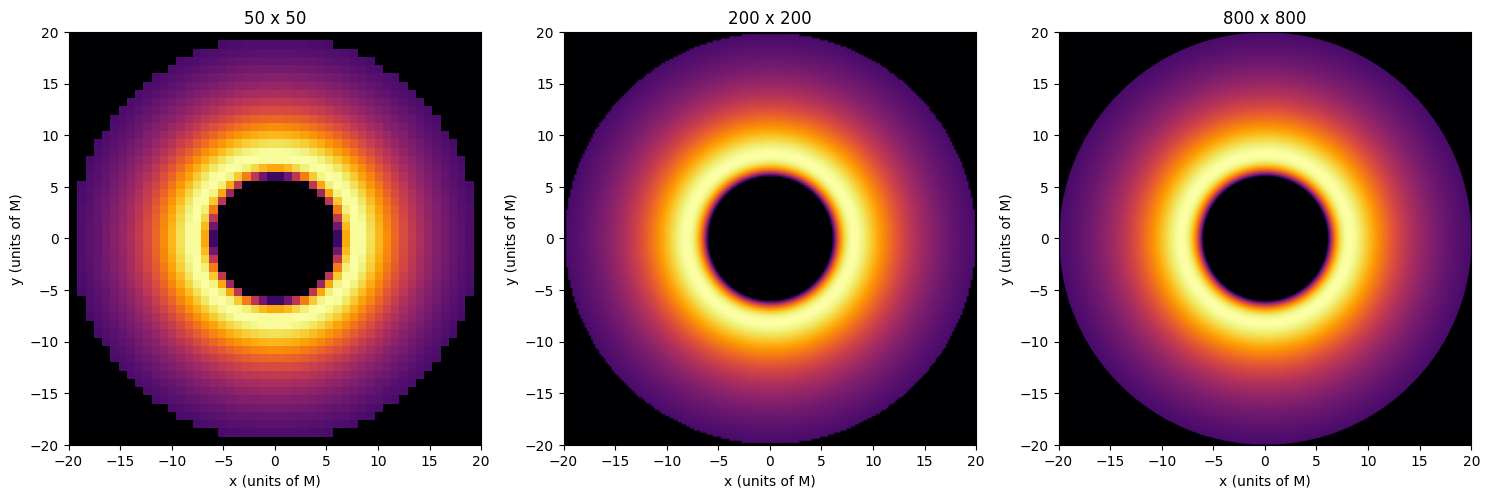

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, resolution in zip(axes, [50, 200, 800]):
    brightness = calculate_disk_brightness(resolution)

    ax.imshow(
        brightness,
        extent=[-20, 20, -20, 20],
        origin="lower",
        cmap="inferno"
    )

    ax.set_title(f"{resolution} x {resolution}")
    ax.set_xlabel("x (units of M)")
    ax.set_ylabel("y (units of M)")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## Performance Experiment Results

### Observations
- Calculation time changes as image resolution increases.
- NumPy vectorization reduces Python-level loop overhead.
- Higher resolutions consume more memory.
- Image quality and computational cost must be balanced.

### Limitations
These experiments measure a simplified brightness calculation,
not a complete black hole ray tracer. They do not benchmark
GPU ray tracing or establish real-time rendering performance.

### Next Steps
- Move reusable physics functions into Python modules.
- Profile the full rendering pipeline.
- Explore GPU acceleration for light-ray calculations.